# Song et al. 2022 — Prostate Cancer · 02 Manifold
Score the three inherited embryonic programs on the malignant manifold, decide branching vs non-branching from the principal graph, root by developmental order, and lay down pseudotime. **Gate 2** (topology) is settled here.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Score the three inherited programs
Gastrulation (Gast), somitogenesis (pSom), neural crest (Crest) scored against the union gene pool; graph-smoothed copies (`*_sm`) give the spatial geography. Raw means are the honest readout for the log.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 4574 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.35
Gast: 71/81 genes present
pSom: 79/98 genes present
Crest: 102/104 genes present
raw module means (honest readout): {'Gast': -0.0127, 'pSom': 0.0248, 'Crest': -0.0223}


### Program geography + proliferation check
Spatial correlations of the smoothed programs decide the axis; the cross-repression pattern (which pair is the dominant inverse gradient) separates a single gradient from a competing-arm bifurcation. Cell-cycle scores are tested against every program — if cycling confounds one program that region would need scoping out (the Zhou/Kürten caveat).

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-compartment smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile distribution across compartments:', frac)
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
print('cycling fraction: %.3f' % adata.obs['cycling'].mean())
for m in ['Gast','pSom','Crest']:
    rho,_ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs cycling score: rho = {rho:+.2f}')
print('-> developmental axis is orthogonal to proliferation; keep whole manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.19
  Crest_sm vs Gast_sm: r = -0.05
  Crest_sm vs pSom_sm: r = -0.85

per-compartment smoothed developmental means:
                   Gast_sm  pSom_sm  Crest_sm
compartment                                  
Luminal-AR-active  -0.0136   0.0274   -0.0236
Luminal-AR-low     -0.0127   0.0077   -0.0137

Crest-high decile distribution across compartments: {'Luminal-AR-low': 0.87, 'Luminal-AR-active': 0.13}
cycling fraction: 0.007
  Gast vs cycling score: rho = -0.03
  pSom vs cycling score: rho = +0.08
  Crest vs cycling score: rho = -0.08
-> developmental axis is orthogonal to proliferation; keep whole manifold (no scoping).


### Branching test — principal graph topology
Fit an unconstrained PPT tree and a curve on the same embedding. A genuine bifurcation requires the tree's arms to resolve *distinct* programs (e.g. one Gast/pSom arm vs one Crest arm). Here all tips carry the same program identity, so the tree is threading one continuous density — the curve is the honest model. The fold self-approach ratio confirms the curve has no artefactual fold.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

# unconstrained tree: do its tips resolve distinct programs?
tre = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(tre, method='ppt', Nodes=30, ppt_lambda=2000, ppt_sigma=0.5,
                use_rep='X_umap', seed=SEED, plot=False, basis='umap')
Bt = np.asarray(tre.uns['graph']['B']); tipst = np.where((Bt>0).sum(0)==1)[0]
forkst = int(((Bt>0).sum(0)>=3).sum())
Rt = np.asarray(tre.obsm['X_R']); hardt = Rt.argmax(1)
Dt = shortest_path(sp.csr_matrix((Bt>0).astype(int)), unweighted=True)
print(f'PPT tree: {len(tipst)} tips, {forkst} forks -- program identity of each tip:')
for tp in tipst:
    m = np.isin(hardt, np.where(Dt[tp]<=3)[0])
    print(f'  tip {tp}: Gast={sub.obs["Gast_sm"][m].mean():+.4f} '
          f'pSom={sub.obs["pSom_sm"][m].mean():+.4f} Crest={sub.obs["Crest_sm"][m].mean():+.4f}')
print('-> all tips share one program profile (no arm isolates a distinct program): forks are spurious.\n')

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'
print('Gate 2: one continuous pSom<->Crest gradient, no competing-arm bifurcation -> GO (non-branching)')
print('Gate 3: no fork -> NA')

PPT tree: 5 tips, 3 forks -- program identity of each tip:
  tip 1: Gast=-0.0149 pSom=+0.0331 Crest=-0.0268
  tip 2: Gast=-0.0150 pSom=+0.0258 Crest=-0.0248
  tip 8: Gast=-0.0135 pSom=+0.0113 Crest=-0.0148
  tip 9: Gast=-0.0136 pSom=+0.0251 Crest=-0.0221
  tip 10: Gast=-0.0096 pSom=+0.0255 Crest=-0.0222
-> all tips share one program profile (no arm isolates a distinct program): forks are spurious.

curve: 2 tips, 0 forks | fold self-approach ratio = 2.93 (>1 = fold-free)
Gate 2: one continuous pSom<->Crest gradient, no competing-arm bifurcation -> GO (non-branching)
Gate 3: no fork -> NA


### Root by developmental order + pseudotime
Neural crest is developmentally *late*, so the root is the Gast/pSom-high, Crest-low tip (never the Crest tip — the Kürten lesson). Pseudotime is laid from that root and its gradient reported.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=-0.0101 pSom=+0.0266 Crest=-0.0230
tip 2: Gast=-0.0134 pSom=+0.0093 Crest=-0.0141
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.539 p=0.0e+00
  pSom_sm: rho=-0.432 p=3.9e-207
  Crest_sm: rho=+0.420 p=4.6e-195
Neural-crest-high decile mean pseudotime = 0.95
Somitogenesis-high decile mean pseudotime = 0.30
Gastrulation-high decile mean pseudotime = 0.30


### Orientation consistency check
The house orientation `X_umap_lin` built in 01 must align with pseudotime (root on the left). Re-used, not re-derived — every UMAP in every notebook shares this frame.

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
assert abs(r) > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = -r
    print('flipped X_umap_lin so pseudotime increases left->right')
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99
variance-axis vs pseudotime-axis disagreement = 1.3deg (small -> equivalent orientation)


### Save + pseudotime manifold panel (`manifold.pdf`)

saved manifold.h5ad + manifold.pdf


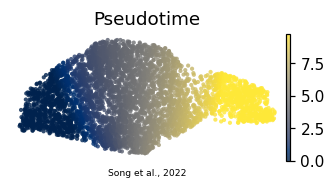

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Song et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')